# 03 · Análisis de las encuestas de percepción

**Datos:** `data/raw/encuestas_percepcion.csv` — 25 encuestas (12 por cuestionario y 13 por audio).

**Objetivo:** convertir respuestas de campo en cifras y gráficos, y cruzarlas con el salario real.

Al terminar sabrás:

1. Cargar las encuestas y contar respuestas (`value_counts`).
2. Crear una variable nueva a partir de otras (categorizar el obstáculo).
3. Hacer gráficos de barras y guardarlos en `figures/`.
4. Cruzar lo que la gente **cree** con lo que **dicen los datos**.
5. Escribir las limitaciones del muestreo (obligatorio en la entrega).

## 1 · Cargar los datos

In [10]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
if not (RAIZ / 'data').exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

FIGURAS = RAIZ / 'figures'
FIGURAS.mkdir(exist_ok=True)

encuestas = pd.read_csv(RAIZ / 'data' / 'raw' / 'encuestas_percepcion.csv')
encuestas.head()

,id,fecha,municipio,origen,sabe_precio,tiempo_para_comprar,confianza_revolico,obstaculo_principal,comentario,transcripcion,verificado
0,E01,2026-10-18,Vedado,cuestionario,No lo sabia,Entre 3 y 5 anos,Depende del precio y del vendedor,El precio es imposible,NaN,NaN,no
1,E02,2026-10-18,Vedado,cuestionario,"Si, se el precio aproximado",Entre 1 y 3 anos,No confio en eso,Miedo a que me lo roben,NaN,NaN,no
2,E03,2026-10-18,Playa,cuestionario,He oido algo pero no se cifras,Nunca podria comprarlo,Depende del precio y del vendedor,Miedo a que me lo roben,NaN,NaN,no
3,E04,2026-10-18,Regla,cuestionario,NaN,NaN,NaN,NaN,NaN,,no
4,E05,2026-10-18,Vedado,cuestionario,No lo sabia,Entre 3 y 5 anos,"Si, lo compraria",Otro: me lo compraria con inversores,NaN,NaN,no


In [11]:
print('Total de encuestas:', len(encuestas))
print()
print(encuestas['origen'].value_counts())

Total de encuestas: 25

origen
audio           13
cuestionario    12
Name: count, dtype: int64


> **Ética:** el CSV no tiene nombres, solo IDs (E01...E25). Los nombres se quedan en el
> cuaderno de campo de la investigadora. Si tuvieras que publicar estos datos,
> municipio + respuestas podrían identificar a alguien en un barrio pequeño.

## 2 · Ver las respuestas crudas

`value_counts()` cuenta cuántas veces aparece cada respuesta. Es el resumen básico de
una encuesta cerrada.

In [12]:
for columna in ['sabe_precio', 'tiempo_para_comprar', 'confianza_revolico', 'obstaculo_principal']:
    print('---', columna, '---')
    print(encuestas[columna].value_counts(dropna=False))
    print()

--- sabe_precio ---
sabe_precio
No lo sabia                       11
He oido algo pero no se cifras     9
Si, se el precio aproximado        3
NaN                                2
Name: count, dtype: int64

--- tiempo_para_comprar ---
tiempo_para_comprar
Nunca podria comprarlo    11
Entre 1 y 3 anos           6
Entre 3 y 5 anos           3
NaN                        3
Menos de 1 ano             1
Mas de 5 anos              1
Name: count, dtype: int64

--- confianza_revolico ---
confianza_revolico
Si, lo compraria                     8
No confio en eso                     5
Depende del precio y del vendedor    4
NaN                                  4
No tengo esos ingresos               4
Name: count, dtype: int64

--- obstaculo_principal ---
obstaculo_principal
El precio es imposible                  12
Miedo a que me lo roben                  5
El dinero                                3
El salario                               2
NaN                                      1
Otro: me lo c

## 3 · Crear una variable nueva: obstáculo económico

En la calle la gente contestó de formas distintas pero con el mismo sentido:
*"el precio es imposible"*, *"el dinero"*, *"el salario"*. Para analizarlo hay que
reunirlas en una sola categoría: **`obstaculo_economico`**.

Así se hace con un **booleano** (`True`/`False`): es un dato derivado, se crea en el
notebook y **no se toca el CSV original**.

In [13]:
economicos = ['El precio es imposible', 'El dinero', 'El salario']

encuestas['obstaculo_economico'] = (
    encuestas['obstaculo_principal'].isin(economicos).fillna(False)
)

print(encuestas['obstaculo_economico'].value_counts())
print()
print('Porcentaje economico: '
      f"{encuestas['obstaculo_economico'].mean() * 100:.0f}%")

obstaculo_economico
True     17
False     8
Name: count, dtype: int64

Porcentaje economico: 68%


## 4 · Gráficos de barras

Se ordenan las categorías de menor a mayor tiempo para que la barra "Nunca podría"
compare bien con las demás. Cada figura se guarda en `figures/` para poder usarla
en el informe sin volver a ejecutar el notebook.

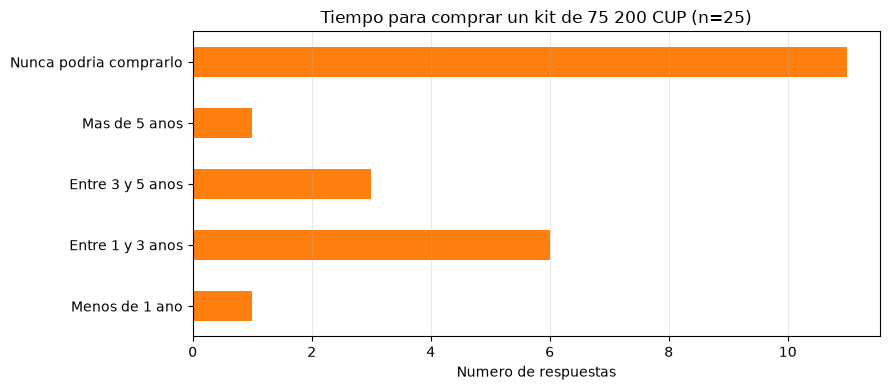

In [5]:
orden_tiempo = [
    'Menos de 1 ano',
    'Entre 1 y 3 anos',
    'Entre 3 y 5 anos',
    'Mas de 5 anos',
    'Nunca podria comprarlo',
]

serie_tiempo = encuestas['tiempo_para_comprar'].value_counts().reindex(orden_tiempo).dropna()

fig, ax = plt.subplots(figsize=(9, 4))
serie_tiempo.plot.barh(ax=ax, color='tab:orange')
ax.set_title('Tiempo para comprar un kit de 75 200 CUP (n=%d)' % len(encuestas))
ax.set_xlabel('Numero de respuestas')
ax.set_ylabel('')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / 'encuestas_tiempo.png', dpi=150)
plt.show()

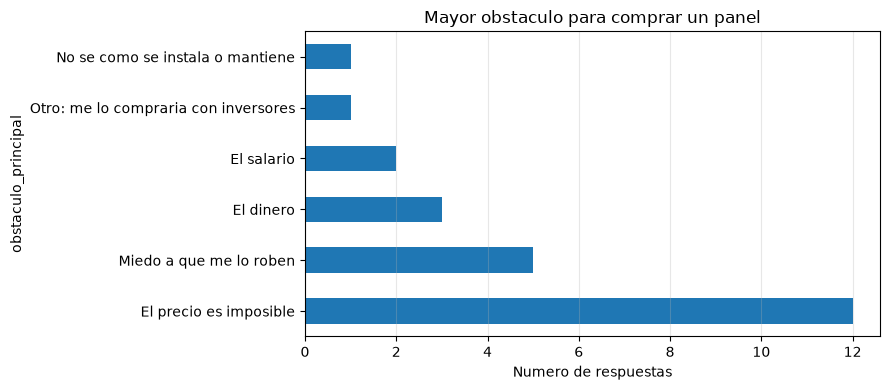

In [6]:
serie_obstaculo = encuestas['obstaculo_principal'].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
serie_obstaculo.plot.barh(ax=ax, color='tab:blue')
ax.set_title('Mayor obstaculo para comprar un panel')
ax.set_xlabel('Numero de respuestas')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / 'encuestas_obstaculos.png', dpi=150)
plt.show()

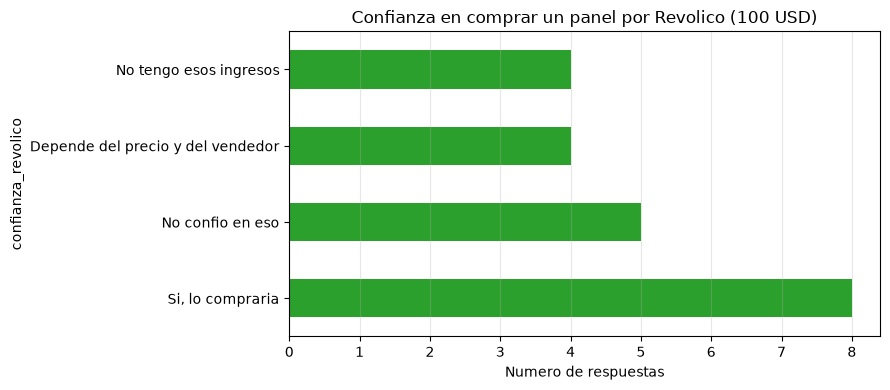

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
encuestas['confianza_revolico'].value_counts().plot.barh(ax=ax, color='tab:green')
ax.set_title('Confianza en comprar un panel por Revolico (100 USD)')
ax.set_xlabel('Numero de respuestas')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURAS / 'encuestas_confianza.png', dpi=150)
plt.show()

## 5 · ¿El cuestionario y los audios dicen lo mismo?

Son dos formas de preguntar. Si coinciden, el resultado es más creíble. Si no,
hay que avisarlo.

In [8]:
tabla = pd.crosstab(encuestas['origen'], encuestas['obstaculo_economico'], normalize='index')
print((tabla * 100).round(0).astype(str) + '%')

obstaculo_economico  False  True 
origen                           
audio                15.0%  85.0%
cuestionario         50.0%  50.0%


## 6 · Cruzar la percepción con los datos duros

El precio usado en las preguntas fue **75 200 CUP** (kit de 800 W de UNE).
¿Cuántos meses de salario medio son?

In [9]:
salarios = pd.read_csv(RAIZ / 'data' / 'raw' / 'salarios_cuba.csv')
salario_2025 = salarios.loc[salarios['anio'] == 2025, 'salario_medio_cup'].iloc[0]
salario_2021 = salarios.loc[salarios['anio'] == 2021, 'salario_medio_cup'].iloc[0]

precio_kit = 75200

print(f'Salario medio 2025: {salario_2025:,.0f} CUP')
print(f'Precio del kit:    {precio_kit:,.0f} CUP')
print(f'Meses de salario:  {precio_kit / salario_2025:.1f} meses')
print(f'Anios de salario:  {precio_kit / salario_2025 / 12:.1f} anios')
print()
print(f'En 2021 serian:    {precio_kit / salario_2021:.1f} meses (salario {salario_2021:,.0f})')

Salario medio 2025: 6,930 CUP
Precio del kit:    75,200 CUP
Meses de salario:  10.9 meses
Anios de salario:  0.9 anios

En 2021 serian:    19.5 meses (salario 3,849)


**Resultado esperado:** el kit cuesta unos 10,8 meses de salario medio, guardando el
*todo* el salario durante casi un año. Pero la gente ahorra una parte, no todo:
por eso las respuestas más frecuentes son "3-5 años" y "nunca".

Esa diferencia entre **lo que dice el cálculo** y **lo que percibe la gente** no es una
contradicción: el cálculo asume que se ahorra el 100 % del salario, lo que en la práctica
no ocurre.

## 7 · Limitaciones (obligatorio en la entrega)

1. **Muestra de conveniencia, no probabilística**: la elegiste tú en la calle, no salió
   de un sorteo. No representa a Cuba ni a La Habana.
2. **n = 25**: muy pequeño para sacar porcentajes "de país". Se usan como **evidencia
   cualitativa apoyada en números**, no como estadística oficial.
3. **Sesgo de zona**: mayoría de La Habana (Vedado, Plaza, Playa...).
4. **Dos instrumentos** (cuestionario y audio) y una pregunta con el vendedor mal
   indicado (Copextel/UNE) según los precios registrados.
5. **E04** solo respondió el municipio; **E06** sin municipio; **E24** no quedó claro
   el tiempo; **E20** no respondió el tiempo.

Con estas salvedades el resultado es defendible: **el precio, no la tecnología, es
la barrera principal**.

## Glosario

| Término | Significado |
|---|---|
| **`value_counts()`** | Cuenta cuántas veces aparece cada valor |
| **Booleano** | Columna `True`/`False` |
| **`isin()`** | ¿Este valor está en una lista? |
| **`crosstab()`** | Tabla cruzada de dos variables |
| **Muestra de conveniencia** | Muestra elegida por acceso fácil, no al azar |
| **Triangulación** | Contrastar un dato con otra fuente independiente |